# Practical 3 — The CV Zoo & Anatomy of YOLO

**A production-grade tour of modern computer vision with PyTorch / torchvision.**

This notebook is organized into two self-contained parts:

| Part | Topic | What you'll build |
|---|---|---|
| **1** | The CV Zoo | An end-to-end inference pipeline across the 4 major CV tasks: classification, object detection, instance segmentation, and semantic segmentation. |
| **2** | Anatomy of YOLO | A from-scratch, vectorized implementation of YOLO's grid-responsibility rule and anchor-box IoU matching, visualized on a real image. |

> **Environment note:** every artifact this notebook needs (sample image, pretrained weights) is fetched automatically at run time — there are no hidden local-file dependencies.


In [1]:
# ============================================================================
# Imports & global configuration
# ============================================================================
from __future__ import annotations

import io
import math
import urllib.request
from dataclasses import dataclass, field
from typing import List, Tuple, Dict

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

import torch
import torch.nn.functional as F
import torchvision
from torchvision.models import resnet50, ResNet50_Weights
from torchvision.models import detection, segmentation
from torchvision.utils import draw_bounding_boxes, draw_segmentation_masks
from torchvision.transforms.functional import to_pil_image, pil_to_tensor
from torchvision.ops import box_iou

plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 150
plt.rcParams["font.size"] = 11

torch.manual_seed(42)
np.random.seed(42)


def get_device() -> torch.device:
    '''Pick the best available accelerator: CUDA > Apple MPS > CPU.'''
    if torch.cuda.is_available():
        return torch.device("cuda")
    if getattr(torch.backends, "mps", None) is not None and torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


DEVICE = get_device()
print(f"Using device: {DEVICE}")


Using device: cpu


## Part 1 — The CV Zoo (Inference Pipeline)

We'll run four state-of-the-art, ImageNet/COCO-pretrained models on a single real-world
street photo (the classic "dog, bicycle, truck" image popularized by the original YOLO
paper). Each task answers a progressively harder question about the same pixels:

1. **Classification** — *"What is the single main thing in this image?"*
2. **Object Detection** — *"Where is every object, and what is it?"* (boxes)
3. **Instance Segmentation** — *"Give me a pixel-perfect mask for every distinct object."*
4. **Semantic Segmentation** — *"Classify every pixel, without separating instances."*


Sample image already cached locally.
Image size: 768 x 576


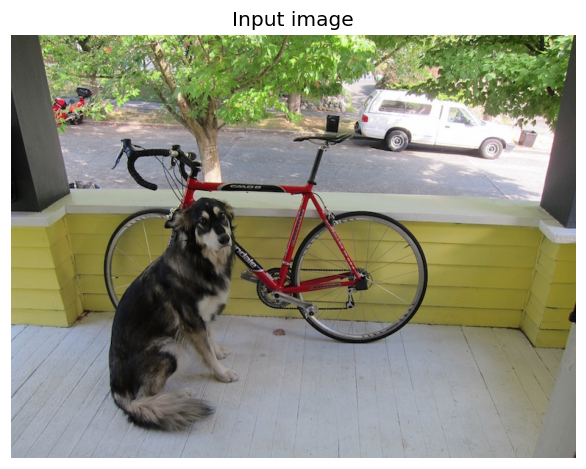

In [2]:
# ============================================================================
# Fetch a sample image (auto-download, cached locally)
# ============================================================================
import os

IMAGE_URL = "https://raw.githubusercontent.com/pjreddie/darknet/master/data/dog.jpg"
IMAGE_PATH = "dog.jpg"

if not os.path.exists(IMAGE_PATH):
    print(f"Downloading sample image from {IMAGE_URL} ...")
    urllib.request.urlretrieve(IMAGE_URL, IMAGE_PATH)
else:
    print("Sample image already cached locally.")

img_pil: Image.Image = Image.open(IMAGE_PATH).convert("RGB")
img_uint8: torch.Tensor = pil_to_tensor(img_pil)          # uint8, shape [3, H, W] — needed by draw_* utils
img_w, img_h = img_pil.size

print(f"Image size: {img_w} x {img_h}")
plt.figure(figsize=(7, 5))
plt.imshow(img_pil)
plt.axis("off")
plt.title("Input image")
plt.show()


### 1.1 Image Classification

We use **ResNet-50** with its official `IMAGENET1K` weights. The modern
`torchvision.models` **Weights Enum API** bundles the correct preprocessing
transform (resize, center-crop, normalize) together with the weights themselves,
so we never have to hand-write normalization constants.


Top-5 predictions:
  malamute                  38.56%
  mountain bike              4.72%
  Eskimo dog                 4.06%
  bicycle-built-for-two      3.90%
  Siberian husky             1.75%


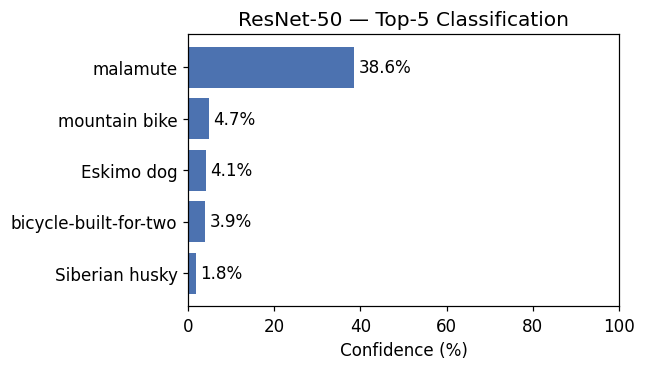

In [3]:
# ============================================================================
# 1.1 Classification — ResNet-50
# ============================================================================
def run_classification(image: Image.Image, top_k: int = 5) -> List[Tuple[str, float]]:
    '''Run ImageNet classification and return the top-k (label, probability) pairs.'''
    weights = ResNet50_Weights.DEFAULT
    model = resnet50(weights=weights).to(DEVICE).eval()
    preprocess = weights.transforms()
    categories = weights.meta["categories"]

    batch = preprocess(image).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        logits = model(batch)
        probs = logits.softmax(dim=1)[0]

    top_probs, top_idxs = probs.topk(top_k)
    return [(categories[i], float(p)) for p, i in zip(top_probs, top_idxs)]


clf_results = run_classification(img_pil, top_k=5)

print("Top-5 predictions:")
for label, prob in clf_results:
    print(f"  {label:<25s} {prob * 100:5.2f}%")

# Visualize as a horizontal bar chart
fig, ax = plt.subplots(figsize=(6, 3.5))
labels = [l for l, _ in clf_results][::-1]
scores = [p * 100 for _, p in clf_results][::-1]
bars = ax.barh(labels, scores, color="#4C72B0")
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set_xlabel("Confidence (%)")
ax.set_xlim(0, 100)
ax.set_title("ResNet-50 — Top-5 Classification")
plt.tight_layout()
plt.show()


### 1.2 Object Detection

We use **Faster R-CNN (ResNet-50-FPN, v2 weights)**. The model outputs, per detected
object, a box $(x_{min}, y_{min}, x_{max}, y_{max})$, a class label, and a confidence
score. We filter predictions with a confidence threshold before drawing them.


Detected 4 objects above threshold:
 - bicycle: 100%
 - dog: 100%
 - truck: 93%
 - motorcycle: 92%


C:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\torchvision\utils.py:375: UserWarning: Argument 'font_size' will be ignored since 'font' is not set.
  warnings.warn("Argument 'font_size' will be ignored since 'font' is not set.")


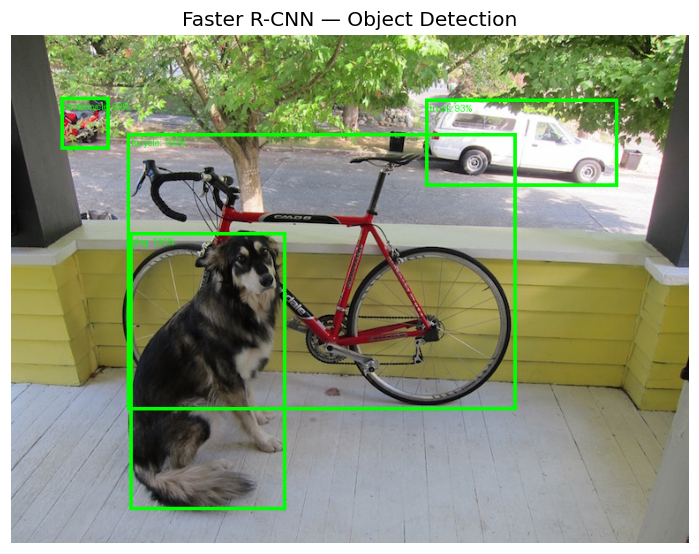

In [4]:
# ============================================================================
# 1.2 Object Detection — Faster R-CNN
# ============================================================================
def run_detection(
    image_tensor: torch.Tensor, score_thresh: float = 0.7
) -> Tuple[torch.Tensor, List[str], List[float]]:
    '''Run Faster R-CNN object detection.

    Returns (kept_boxes[N,4], kept_labels, kept_scores) after score thresholding.
    '''
    weights = detection.FasterRCNN_ResNet50_FPN_V2_Weights.DEFAULT
    model = detection.fasterrcnn_resnet50_fpn_v2(weights=weights).to(DEVICE).eval()
    categories = weights.meta["categories"]
    preprocess = weights.transforms()

    batch = preprocess(image_tensor).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        pred = model(batch)[0]

    keep = pred["scores"] > score_thresh
    boxes = pred["boxes"][keep].cpu()
    labels = [categories[i] for i in pred["labels"][keep].cpu()]
    scores = [float(s) for s in pred["scores"][keep].cpu()]
    return boxes, labels, scores


det_boxes, det_labels, det_scores = run_detection(img_uint8, score_thresh=0.7)
det_captions = [f"{l}: {s:.0%}" for l, s in zip(det_labels, det_scores)]

print(f"Detected {len(det_labels)} objects above threshold:")
for cap in det_captions:
    print(" -", cap)

det_vis = draw_bounding_boxes(
    img_uint8, det_boxes, labels=det_captions, colors="lime", width=4, font_size=20
)
plt.figure(figsize=(8, 6))
plt.imshow(to_pil_image(det_vis))
plt.axis("off")
plt.title("Faster R-CNN — Object Detection")
plt.show()


### 1.3 Instance Segmentation

**Mask R-CNN** extends Faster R-CNN with a per-object binary mask branch, giving a
pixel-precise outline for every *individual* instance (two dogs would get two separate
masks, even if they overlap).


Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_v2_coco-73cbd019.pth" to C:\Users\User/.cache\torch\hub\checkpoints\maskrcnn_resnet50_fpn_v2_coco-73cbd019.pth


100%|███████████████████████████████████████████████████████████████████████████████| 177M/177M [00:31<00:00, 5.99MB/s]


Segmented 5 instances above threshold:
 - bicycle: 100%
 - dog: 99%
 - car: 92%
 - motorcycle: 89%
 - truck: 71%


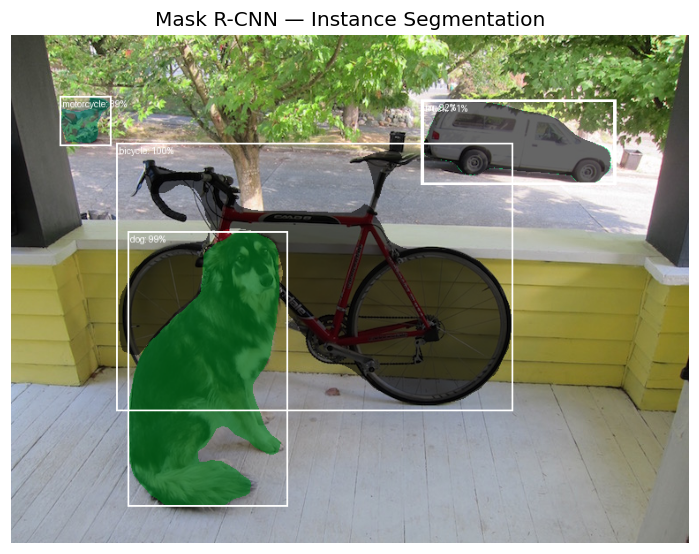

In [5]:
# ============================================================================
# 1.3 Instance Segmentation — Mask R-CNN
# ============================================================================
def run_instance_segmentation(
    image_tensor: torch.Tensor, score_thresh: float = 0.7, mask_thresh: float = 0.5
) -> Tuple[torch.Tensor, torch.Tensor, List[str], List[float]]:
    '''Run Mask R-CNN instance segmentation.

    Returns (boxes, boolean_masks[N,H,W], labels, scores).
    '''
    weights = detection.MaskRCNN_ResNet50_FPN_V2_Weights.DEFAULT
    model = detection.maskrcnn_resnet50_fpn_v2(weights=weights).to(DEVICE).eval()
    categories = weights.meta["categories"]
    preprocess = weights.transforms()

    batch = preprocess(image_tensor).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        pred = model(batch)[0]

    keep = pred["scores"] > score_thresh
    boxes = pred["boxes"][keep].cpu()
    # pred["masks"] is [N, 1, H, W] soft probability maps -> binarize
    masks = (pred["masks"][keep, 0] > mask_thresh).cpu()
    labels = [categories[i] for i in pred["labels"][keep].cpu()]
    scores = [float(s) for s in pred["scores"][keep].cpu()]
    return boxes, masks, labels, scores


inst_boxes, inst_masks, inst_labels, inst_scores = run_instance_segmentation(img_uint8)
inst_captions = [f"{l}: {s:.0%}" for l, s in zip(inst_labels, inst_scores)]

print(f"Segmented {len(inst_labels)} instances above threshold:")
for cap in inst_captions:
    print(" -", cap)

inst_vis = draw_segmentation_masks(img_uint8, inst_masks, alpha=0.6)
inst_vis = draw_bounding_boxes(inst_vis, inst_boxes, labels=inst_captions, colors="white", width=2)

plt.figure(figsize=(8, 6))
plt.imshow(to_pil_image(inst_vis))
plt.axis("off")
plt.title("Mask R-CNN — Instance Segmentation")
plt.show()


### 1.4 Semantic Segmentation

**DeepLabV3 (ResNet-50 backbone)** classifies *every pixel* into one of the Pascal
VOC classes. Unlike instance segmentation, two objects of the same class (e.g. two
dogs) are merged into a single "dog" region — there's no notion of separate instances.

The model returns a tensor of shape `[num_classes, H, W]` of per-class logits; we take
an `argmax` over the class dimension to get one label per pixel.


Downloading: "https://download.pytorch.org/models/deeplabv3_resnet50_coco-cd0a2569.pth" to C:\Users\User/.cache\torch\hub\checkpoints\deeplabv3_resnet50_coco-cd0a2569.pth


100%|███████████████████████████████████████████████████████████████████████████████| 161M/161M [00:28<00:00, 5.99MB/s]


Classes found in the scene: ['bicycle', 'car', 'dog']


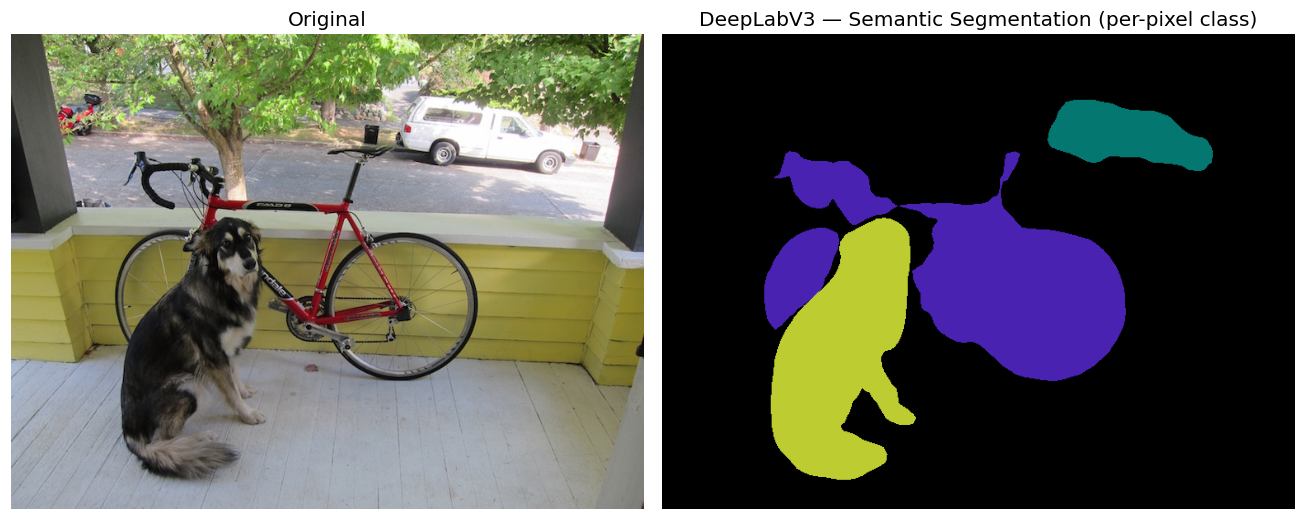

In [6]:
# ============================================================================
# 1.4 Semantic Segmentation — DeepLabV3
# ============================================================================
def run_semantic_segmentation(image_tensor: torch.Tensor) -> Tuple[torch.Tensor, List[str]]:
    '''Run DeepLabV3 semantic segmentation.

    Returns (per_pixel_class_map [H, W] long tensor, category_names).
    '''
    weights = segmentation.DeepLabV3_ResNet50_Weights.DEFAULT
    model = segmentation.deeplabv3_resnet50(weights=weights).to(DEVICE).eval()
    categories = weights.meta["categories"]
    preprocess = weights.transforms()

    batch = preprocess(image_tensor).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        out = model(batch)["out"][0]           # [num_classes, H, W]

    class_map = out.argmax(0).cpu()             # [H, W], values in [0, num_classes)
    return class_map, categories


sem_class_map, sem_categories = run_semantic_segmentation(img_uint8)
present_classes = [sem_categories[i] for i in sem_class_map.unique().tolist() if i != 0]
print("Classes found in the scene:", present_classes)

# Build a deterministic color palette and colorize the class map
palette = torch.tensor(
    [(i * 37 % 255, i * 17 % 255, i * 89 % 255) for i in range(len(sem_categories))],
    dtype=torch.uint8,
)
palette[0] = torch.tensor([0, 0, 0])  # background -> black
color_map = palette[sem_class_map]    # [H, W, 3]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(img_pil)
axes[0].set_title("Original")
axes[0].axis("off")
axes[1].imshow(color_map.numpy())
axes[1].set_title("DeepLabV3 — Semantic Segmentation (per-pixel class)")
axes[1].axis("off")
plt.tight_layout()
plt.show()


### 1.5 Side-by-Side: The Full CV Zoo

One montage that summarizes all four tasks on the same input image — a useful mental
map of "what changes" as we move from a single label to per-pixel, per-instance
understanding.


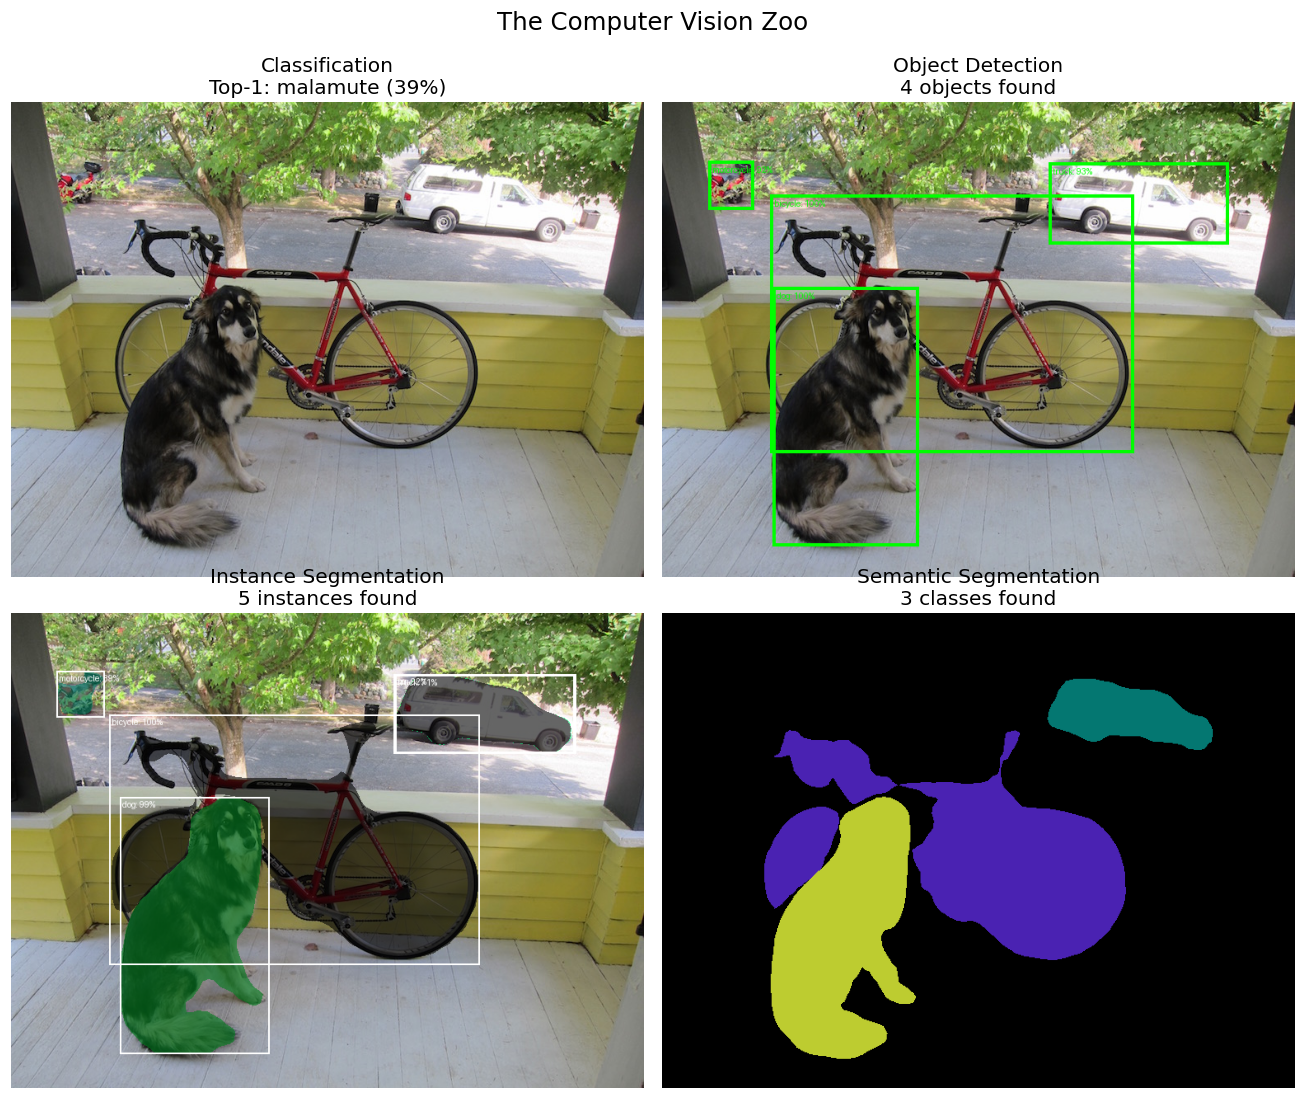

In [7]:
# ============================================================================
# 1.5 Comparison montage
# ============================================================================
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

axes[0, 0].imshow(img_pil)
top1_label, top1_prob = clf_results[0]
axes[0, 0].set_title(f"Classification\nTop-1: {top1_label} ({top1_prob:.0%})")
axes[0, 0].axis("off")

axes[0, 1].imshow(to_pil_image(det_vis))
axes[0, 1].set_title(f"Object Detection\n{len(det_labels)} objects found")
axes[0, 1].axis("off")

axes[1, 0].imshow(to_pil_image(inst_vis))
axes[1, 0].set_title(f"Instance Segmentation\n{len(inst_labels)} instances found")
axes[1, 0].axis("off")

axes[1, 1].imshow(color_map.numpy())
axes[1, 1].set_title(f"Semantic Segmentation\n{len(present_classes)} classes found")
axes[1, 1].axis("off")

plt.suptitle("The Computer Vision Zoo", fontsize=16, y=1.0)
plt.tight_layout()
plt.show()


## Part 2 — Anatomy of YOLO (Grid Responsibility & Anchors)

The CV Zoo models above are all **two-stage or dense-but-separate** pipelines: a
region proposal step (or a per-pixel head) followed by classification. **YOLO**
("You Only Look Once") takes a different approach — it reformulates detection as a
single regression problem over a spatial grid. This section builds YOLO's core
mechanics from scratch, on the *same* real image, so the grid math is grounded in
pixels you can already recognize.

We will:

1. Overlay an $S \times S$ grid on the image and derive the ground-truth boxes.
2. Compute, for every object, **which grid cell is "responsible"** for it.
3. Define a small set of **anchor box** templates and compute $IoU$ against the
   ground truth to see which anchor "wins" the assignment.
4. Visualize the responsible cell + matched anchor + ground-truth box together.


Image size: 768 x 576
  dog      -> xyxy = (130, 220, 310, 540)
  bicycle  -> xyxy = (115, 120, 575, 445)
  truck    -> xyxy = (460, 70, 690, 175)


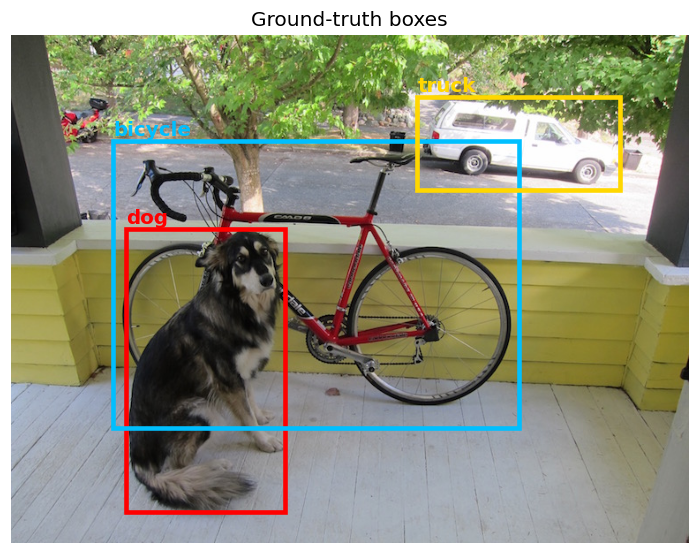

In [8]:
# ============================================================================
# 2.0 Ground-truth boxes for the sample image
# ============================================================================
# Hand-labeled ground truth for dog.jpg (VOC-style: [xmin, ymin, xmax, ymax])
img_voc = Image.open(IMAGE_PATH).convert("RGB")
img_w, img_h = img_voc.size

ground_truth: Dict[str, Tuple[int, int, int, int]] = {
    "dog":     (130, 220, 310, 540),
    "bicycle": (115, 120, 575, 445),
    "truck":   (460, 70, 690, 175),
}

print(f"Image size: {img_w} x {img_h}")
for name, box in ground_truth.items():
    print(f"  {name:<8s} -> xyxy = {box}")

fig, ax = plt.subplots(figsize=(8, 6))
ax.imshow(img_voc)
colors = {"dog": "red", "bicycle": "deepskyblue", "truck": "gold"}
for name, (xmin, ymin, xmax, ymax) in ground_truth.items():
    rect = patches.Rectangle(
        (xmin, ymin), xmax - xmin, ymax - ymin,
        linewidth=3, edgecolor=colors[name], facecolor="none",
    )
    ax.add_patch(rect)
    ax.text(xmin, ymin - 6, name, color=colors[name], fontsize=13, fontweight="bold")
ax.set_title("Ground-truth boxes")
ax.axis("off")
plt.show()


### 2.1 The YOLO Grid & "Responsibility"

YOLO divides the image into an $S \times S$ grid of cells. Each cell has width
$w_{cell} = \dfrac{W_{img}}{S}$ and height $h_{cell} = \dfrac{H_{img}}{S}$.

**The Golden Rule:** *the grid cell that contains the center $(x_c, y_c)$ of an
object's ground-truth box is the one "responsible" for predicting that object.*

Given an object center $(x_c, y_c)$, its responsible cell indices $(i, j)$
(column, row) are:

$$
i = \left\lfloor \frac{x_c}{w_{cell}} \right\rfloor, \qquad
j = \left\lfloor \frac{y_c}{h_{cell}} \right\rfloor
$$

Below we compute this **vectorized** — for every ground-truth box at once, with
no Python-level loop over boxes.


In [9]:
# ============================================================================
# 2.1 Vectorized grid-cell responsibility
# ============================================================================
def boxes_xyxy_to_centers(boxes: np.ndarray) -> np.ndarray:
    '''Convert [N, 4] xyxy boxes to [N, 2] (x_center, y_center).'''
    xmin, ymin, xmax, ymax = boxes[:, 0], boxes[:, 1], boxes[:, 2], boxes[:, 3]
    cx = (xmin + xmax) / 2.0
    cy = (ymin + ymax) / 2.0
    return np.stack([cx, cy], axis=1)


def responsible_cells(
    centers: np.ndarray, img_size: Tuple[int, int], grid_size: int
) -> np.ndarray:
    '''Vectorized computation of (grid_col, grid_row) for every object center.

    Args:
        centers: [N, 2] array of (x_center, y_center) in pixel coordinates.
        img_size: (img_w, img_h).
        grid_size: S, the grid is S x S.

    Returns:
        [N, 2] integer array of (grid_col, grid_row), each clipped to [0, S-1].
    '''
    img_w, img_h = img_size
    cell_w, cell_h = img_w / grid_size, img_h / grid_size
    cols = np.floor(centers[:, 0] / cell_w).astype(int)
    rows = np.floor(centers[:, 1] / cell_h).astype(int)
    cols = np.clip(cols, 0, grid_size - 1)
    rows = np.clip(rows, 0, grid_size - 1)
    return np.stack([cols, rows], axis=1)


S = 7  # classic YOLOv1 grid size
names = list(ground_truth.keys())
gt_boxes_arr = np.array([ground_truth[n] for n in names], dtype=np.float32)
centers = boxes_xyxy_to_centers(gt_boxes_arr)
cells_ij = responsible_cells(centers, (img_w, img_h), S)

cell_w, cell_h = img_w / S, img_h / S
print(f"Grid: {S} x {S}  |  cell size: {cell_w:.1f}px x {cell_h:.1f}px\n")
for name, (cx, cy), (col, row) in zip(names, centers, cells_ij):
    print(f"  {name:<8s} center=({cx:6.1f}, {cy:6.1f}) -> responsible cell (col={col}, row={row})")


Grid: 7 x 7  |  cell size: 109.7px x 82.3px

  dog      center=( 220.0,  380.0) -> responsible cell (col=2, row=4)
  bicycle  center=( 345.0,  282.5) -> responsible cell (col=3, row=3)
  truck    center=( 575.0,  122.5) -> responsible cell (col=5, row=1)


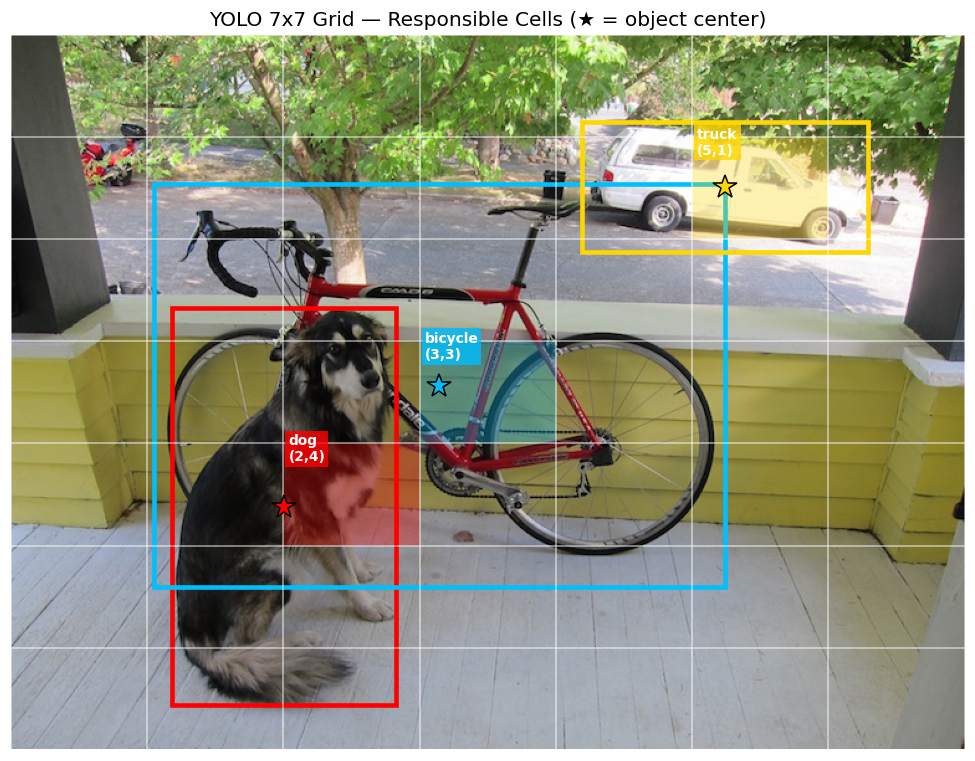

In [10]:
# ============================================================================
# 2.1b Visualize the grid + responsible cells
# ============================================================================
fig, ax = plt.subplots(figsize=(9, 7))
ax.imshow(img_voc)

# Draw the S x S grid lines
for k in range(S + 1):
    ax.axvline(k * cell_w, color="white", linewidth=1, alpha=0.6)
    ax.axhline(k * cell_h, color="white", linewidth=1, alpha=0.6)

# Highlight each responsible cell + draw its GT box + center dot
for name, box, (cx, cy), (col, row) in zip(names, gt_boxes_arr, centers, cells_ij):
    color = colors[name]
    xmin, ymin, xmax, ymax = box
    ax.add_patch(patches.Rectangle(
        (xmin, ymin), xmax - xmin, ymax - ymin,
        linewidth=3, edgecolor=color, facecolor="none",
    ))
    ax.add_patch(patches.Rectangle(
        (col * cell_w, row * cell_h), cell_w, cell_h,
        linewidth=0, facecolor=color, alpha=0.30,
    ))
    ax.plot(cx, cy, marker="*", markersize=16, color=color, markeredgecolor="black")
    ax.text(
        col * cell_w + 4, row * cell_h + 14, f"{name}\n({col},{row})",
        color="white", fontsize=9, fontweight="bold",
        bbox=dict(facecolor=color, alpha=0.8, pad=2, edgecolor="none"),
    )

ax.set_xlim(0, img_w)
ax.set_ylim(img_h, 0)
ax.set_title(f"YOLO {S}x{S} Grid — Responsible Cells (★ = object center)")
ax.axis("off")
plt.tight_layout()
plt.show()


### 2.2 Decoding the Network Output Tensor

For a grid of size $S \times S$ with $B$ anchor boxes per cell and $C$ classes, YOLO's
raw output tensor has shape:

$$
S \times S \times (B \cdot 5 + C)
$$

Each of the $B$ anchors at a cell predicts 5 numbers — $(t_x, t_y, t_w, t_h,\, \text{objectness})$
— plus the cell shares one class-probability vector of length $C$. The "5" is: box
center offset $(t_x, t_y)$ within the cell, box size $(t_w, t_h)$ relative to the
anchor template, and an objectness confidence score.

Before training can even begin, YOLO needs to decide **which of the $B$ anchors at
the responsible cell is "in charge"** of matching a given ground-truth box. That's
what $IoU$-based anchor matching (next section) solves.


### 2.3 Anchor Boxes & Intersection-over-Union (IoU)

Each grid cell is given $B$ **anchor box templates** — fixed-shape priors (e.g. one
"short & wide" box, one "tall & skinny" box, one "large square" box) centered on the
cell. During training, YOLO computes the $IoU$ between the ground-truth box and each
anchor template (both centered at the same point), and the anchor with the **highest
IoU** is assigned responsibility for regressing to that ground truth.

**IoU** between two axis-aligned boxes $A$ and $B$ is defined as:

$$
IoU(A, B) = \frac{\text{Area}(A \cap B)}{\text{Area}(A \cup B)}
          = \frac{\text{Area}(A \cap B)}{\text{Area}(A) + \text{Area}(B) - \text{Area}(A \cap B)}
$$

$IoU \in [0, 1]$: $0$ means no overlap, $1$ means a perfect match.


In [11]:
# ============================================================================
# 2.3a Vectorized IoU (fully custom, NumPy — no loops)
# ============================================================================
def calculate_iou_matrix(boxes1: np.ndarray, boxes2: np.ndarray) -> np.ndarray:
    '''Pairwise IoU between two sets of axis-aligned boxes, fully vectorized.

    Args:
        boxes1: [N, 4] array of (xmin, ymin, xmax, ymax).
        boxes2: [M, 4] array of (xmin, ymin, xmax, ymax).

    Returns:
        [N, M] IoU matrix.
    '''
    boxes1 = boxes1[:, None, :]   # [N, 1, 4] -> broadcast against M
    boxes2 = boxes2[None, :, :]   # [1, M, 4]

    inter_xmin = np.maximum(boxes1[..., 0], boxes2[..., 0])
    inter_ymin = np.maximum(boxes1[..., 1], boxes2[..., 1])
    inter_xmax = np.minimum(boxes1[..., 2], boxes2[..., 2])
    inter_ymax = np.minimum(boxes1[..., 3], boxes2[..., 3])

    inter_w = np.clip(inter_xmax - inter_xmin, a_min=0, a_max=None)
    inter_h = np.clip(inter_ymax - inter_ymin, a_min=0, a_max=None)
    inter_area = inter_w * inter_h

    area1 = (boxes1[..., 2] - boxes1[..., 0]) * (boxes1[..., 3] - boxes1[..., 1])
    area2 = (boxes2[..., 2] - boxes2[..., 0]) * (boxes2[..., 3] - boxes2[..., 1])
    union_area = area1 + area2 - inter_area

    return inter_area / np.clip(union_area, a_min=1e-9, a_max=None)


# Sanity-check the custom implementation against torchvision.ops.box_iou
_a = np.array([[0, 0, 10, 10]], dtype=np.float32)
_b = np.array([[5, 5, 15, 15], [0, 0, 10, 10], [20, 20, 30, 30]], dtype=np.float32)
_custom = calculate_iou_matrix(_a, _b)
_reference = box_iou(torch.tensor(_a), torch.tensor(_b)).numpy()
assert np.allclose(_custom, _reference, atol=1e-6), "Custom IoU does not match torchvision reference!"
print("Custom vectorized IoU matches torchvision.ops.box_iou ✔")
print("Sanity check IoUs:", _custom.round(3))


Custom vectorized IoU matches torchvision.ops.box_iou ✔
Sanity check IoUs: [[0.143 1.    0.   ]]


In [12]:
# ============================================================================
# 2.3b Define anchor templates and match against every ground-truth box
# ============================================================================
# (width, height) templates, in pixels, chosen to be a wide/tall/square trio
ANCHOR_TEMPLATES: Dict[str, Tuple[float, float]] = {
    "wide":   (260.0, 120.0),   # short & wide  (e.g. vehicles)
    "tall":   (140.0, 300.0),   # tall & skinny (e.g. standing animals/people)
    "square": (220.0, 220.0),   # large, roughly square (e.g. compact/sprawling objects)
}
anchor_names = list(ANCHOR_TEMPLATES.keys())
anchor_wh = np.array(list(ANCHOR_TEMPLATES.values()), dtype=np.float32)


def anchors_at_cell_center(
    cell_center: Tuple[float, float], anchor_wh: np.ndarray
) -> np.ndarray:
    '''Place every anchor template centered at `cell_center`; return xyxy boxes [M, 4].'''
    cx, cy = cell_center
    w, h = anchor_wh[:, 0], anchor_wh[:, 1]
    xmin, ymin = cx - w / 2, cy - h / 2
    xmax, ymax = cx + w / 2, cy + h / 2
    return np.stack([xmin, ymin, xmax, ymax], axis=1)


best_anchor_idx = np.zeros(len(names), dtype=int)
best_anchor_iou = np.zeros(len(names), dtype=np.float32)
anchor_boxes_per_obj = []

print(f"{'Object':<10s}{'wide':>8s}{'tall':>8s}{'square':>8s}   Winner")
for k, (name, (col, row)) in enumerate(zip(names, cells_ij)):
    cell_center = (col * cell_w + cell_w / 2, row * cell_h + cell_h / 2)
    anchors_xyxy = anchors_at_cell_center(cell_center, anchor_wh)  # [3, 4]
    gt_box = gt_boxes_arr[k : k + 1]                               # [1, 4]

    ious = calculate_iou_matrix(gt_box, anchors_xyxy)[0]           # [3]
    winner = int(np.argmax(ious))

    best_anchor_idx[k] = winner
    best_anchor_iou[k] = ious[winner]
    anchor_boxes_per_obj.append(anchors_xyxy)

    row_str = "".join(f"{iou:8.3f}" for iou in ious)
    print(f"{name:<10s}{row_str}   {anchor_names[winner]} (IoU={ious[winner]:.3f})")


Object        wide    tall  square   Winner
dog          0.289   0.467   0.434   tall (IoU=0.467)
bicycle      0.209   0.281   0.324   square (IoU=0.324)
truck        0.697   0.286   0.398   wide (IoU=0.697)


### 2.4 Putting It All Together

For each object we now visualize, in a single frame:

- The **ground-truth box** (solid color outline).
- The **responsible grid cell**, shaded.
- **All three anchor templates**, drawn (dashed) centered on that cell.
- The **winning anchor** (highest IoU), highlighted with a thick border.


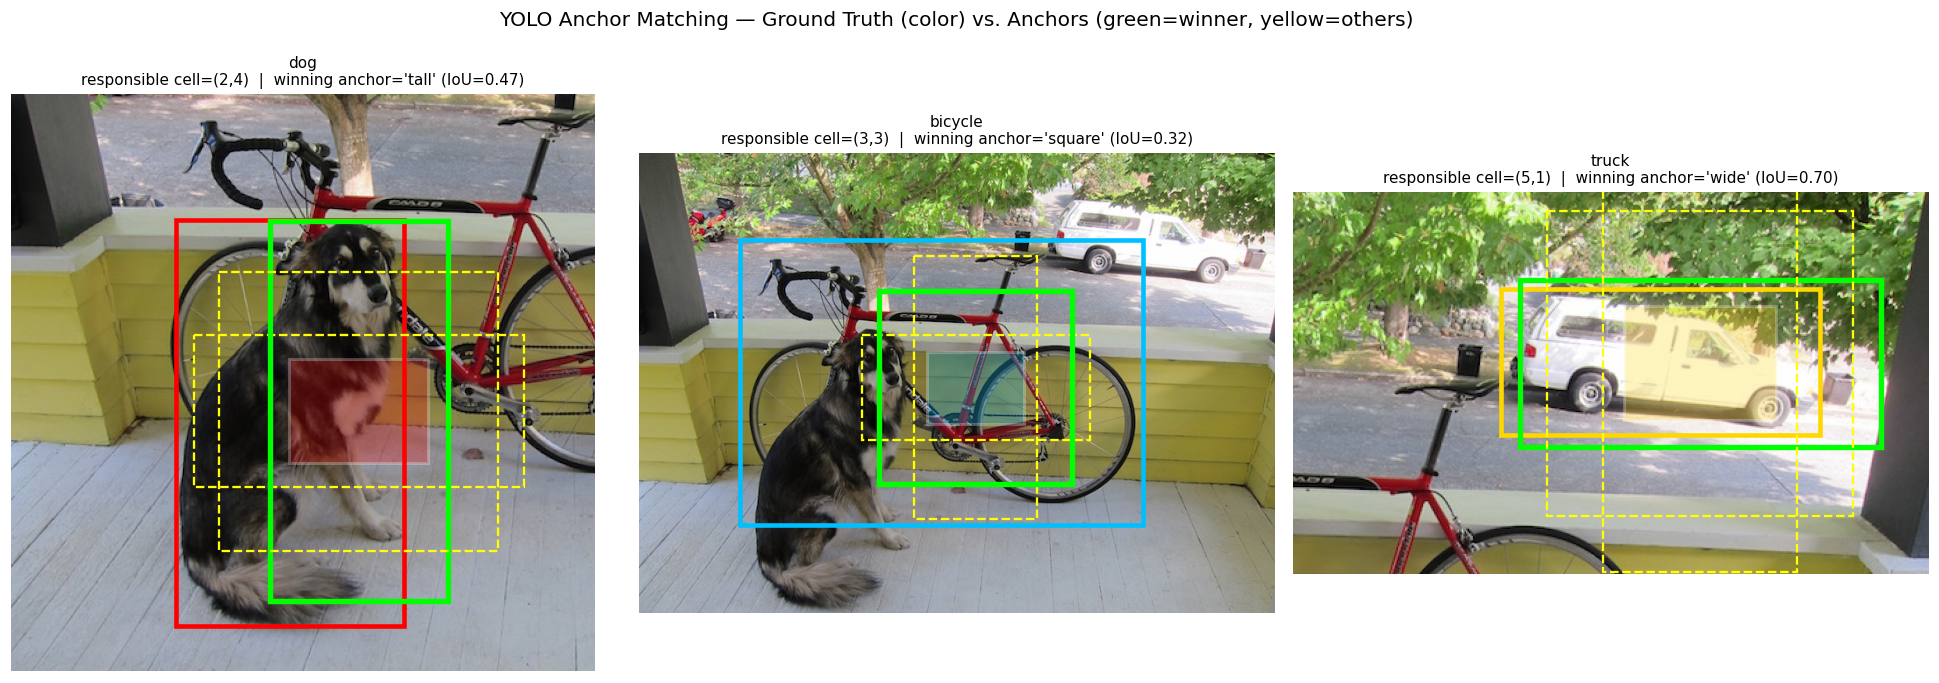

In [13]:
# ============================================================================
# 2.4 Final visualization — GT box, grid cell, and matched anchor
# ============================================================================
fig, axes = plt.subplots(1, len(names), figsize=(6 * len(names), 6))
if len(names) == 1:
    axes = [axes]

for ax, name, gt_box, (col, row), anchors_xyxy, winner, iou in zip(
    axes, names, gt_boxes_arr, cells_ij, anchor_boxes_per_obj, best_anchor_idx, best_anchor_iou
):
    ax.imshow(img_voc)
    color = colors[name]

    # Responsible cell (shaded)
    ax.add_patch(patches.Rectangle(
        (col * cell_w, row * cell_h), cell_w, cell_h,
        linewidth=2, edgecolor="white", facecolor=color, alpha=0.25,
    ))

    # Ground truth box (solid)
    xmin, ymin, xmax, ymax = gt_box
    ax.add_patch(patches.Rectangle(
        (xmin, ymin), xmax - xmin, ymax - ymin,
        linewidth=3, edgecolor=color, facecolor="none", label="Ground truth",
    ))

    # All anchor templates (dashed), winner highlighted (thick solid)
    for a_idx, (ax_xmin, ax_ymin, ax_xmax, ax_ymax) in enumerate(anchors_xyxy):
        is_winner = a_idx == winner
        ax.add_patch(patches.Rectangle(
            (ax_xmin, ax_ymin), ax_xmax - ax_xmin, ax_ymax - ax_ymin,
            linewidth=3.5 if is_winner else 1.5,
            edgecolor="lime" if is_winner else "yellow",
            facecolor="none",
            linestyle="-" if is_winner else "--",
        ))

    ax.set_title(
        f"{name}\nresponsible cell=({col},{row})  |  "
        f"winning anchor='{anchor_names[winner]}' (IoU={iou:.2f})",
        fontsize=10,
    )
    ax.set_xlim(max(0, xmin - 150), min(img_w, xmax + 150))
    ax.set_ylim(min(img_h, ymax + 100), max(0, ymin - 100))
    ax.axis("off")

plt.suptitle("YOLO Anchor Matching — Ground Truth (color) vs. Anchors (green=winner, yellow=others)", y=1.03)
plt.tight_layout()
plt.show()


## Summary & Key Takeaways

- **The CV Zoo**: classification, detection, instance segmentation, and semantic
  segmentation form a natural hierarchy of *"how much spatial detail do we ask the
  model to output?"* — from one label per image, to boxes, to per-instance masks,
  to per-pixel classes. All four are one line away thanks to torchvision's
  pretrained **Weights Enum API**.
- **YOLO's grid responsibility rule** turns "where is the object" into a simple
  floor-division of the object's center coordinates by the cell size — fully
  vectorizable, no proposal network required.
- **Anchor + IoU matching** resolves the remaining ambiguity of *box shape*: rather
  than regressing raw pixel coordinates, YOLO regresses small offsets from the
  best-fitting anchor template, which is what makes training stable.

Together, these two parts explain both *what* modern CV models can do (Part 1) and
*why* a single-shot detector like YOLO can do detection so much faster than a
two-stage pipeline (Part 2).
